# Metro Interstate Traffic Volume Prediction

**An end-to-end machine learning pipeline to predict hourly I-94 traffic volume from meteorological and temporal features.**

This notebook consolidates the multi-stage preprocessing, anomaly cleaning, leakage-free scaling, model selection, and hyperparameter tuning workflow into a single reproducible pipeline.


## Project Workflow

1. **Load & Inspect Data:** Examine raw dimensions, data types, and missing values.
2. **Holiday Encoding:** Propagate holiday labels across full calendar days and one-hot encode grouped holiday tiers.
3. **Weather Categorization:** Consolidate granular weather descriptions into binary severity indicators.
4. **Timestamp Aggregation & Temporal Extraction:** Resolve duplicate hourly timestamps and extract `hour`, `day_of_week`, and `month`.
5. **Sensor Anomaly & Outage Filtering:** Remove corrupted `0 K` temperature readings and verified sensor outage/closure records (`traffic_volume <= 110`).
6. **Leakage-Free Split & Scaling:** Partition into 70% Train / 15% Validation / 15% Test sets and fit `StandardScaler` strictly on `X_train`.
7. **Baseline Linear Regression:** Evaluate linear assumptions on cyclical time features.
8. **Random Forest & Regularization:** Train a default Random Forest, diagnose overfitting, and apply structural pruning (`max_depth`, `min_samples_leaf`).
9. **Hyperparameter Optimization (`RandomizedSearchCV`):** Search continuous `scipy.stats` distributions to minimize validation RMSE.
10. **Final Test Set Evaluation:** Perform a single unbiased evaluation on the reserved `X_test` split.

## 1. Import required modules

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform
from IPython.display import display

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
DATA_PATH = Path("Metro_Interstate_Traffic_Volume.csv")

## 2. Load and Inspect the Raw Dataset

Load the original dataset and inspect its shape, column types, and missing values prior to transformation.

In [8]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Place the CSV next to this notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 48,204 | Columns: 9


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [9]:
print("Column names:", df_raw.columns.tolist())
print("\nRaw Dataset Info:")
df_raw.info()

Column names: ['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

Raw Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


## 3. Preprocessing

In the raw dataset, holiday labels only appear on the `00:00:00` midnight of a holiday rather than across all 24 hours. We propagate the holiday label across the entire day, group holidays into `Major_Holiday`, `Minor_Holiday`, `State_Fair`, and `Normal_Day`, and one-hot encode them (dropping `Normal_Day` as the reference baseline). The redundant `weather_main` column is also dropped.

## Stage 1

In [10]:
df_stage1 = df_raw.copy()
df_stage1 = df_stage1.drop(columns=["weather_main"])

# Propagate midnight holiday labels across entire 24 hours of the same day
df_stage1["date_time"] = pd.to_datetime(df_stage1["date_time"])
df_stage1["date"] = df_stage1["date_time"].dt.date

df_stage1["holiday"] = df_stage1["holiday"].replace("None", pd.NA)
df_stage1["holiday"] = df_stage1.groupby("date")["holiday"].transform(lambda s: s.ffill().bfill())
df_stage1["holiday"] = df_stage1["holiday"].fillna("None")

major_holidays = [
    "Labor Day", "Thanksgiving Day", "Christmas Day",
    "New Years Day", "Memorial Day", "Independence Day"
]
minor_holidays = [
    "Martin Luther King Jr Day", "Columbus Day",
    "Veterans Day", "Washingtons Birthday"
]

def categorize_holiday(holiday_name):
    if holiday_name in major_holidays:
        return "Major_Holiday"
    if holiday_name in minor_holidays:
        return "Minor_Holiday"
    if holiday_name == "State Fair":
        return "State_Fair"
    return "Normal_Day"

df_stage1["holiday_category"] = df_stage1["holiday"].apply(categorize_holiday)
df_stage1 = pd.get_dummies(
    df_stage1,
    columns=["holiday_category"],
    prefix="",
    prefix_sep="",
    drop_first=False,
    dtype="int64"
)
df_stage1 = df_stage1.drop(columns=["Normal_Day", "holiday", "date"])

print(f"Dataset after Stage 1 implementation: {len(df_stage1):,}")
display(df_stage1.head())

Dataset after Stage 1 implementation: 48,204


,temp,rain_1h,snow_1h,clouds_all,weather_description,date_time,traffic_volume,Major_Holiday,Minor_Holiday,State_Fair
0,288.28,0.0,0.0,40,scattered clouds,2012-10-02 09:00:00,5545,0,0,0
1,289.36,0.0,0.0,75,broken clouds,2012-10-02 10:00:00,4516,0,0,0
2,289.58,0.0,0.0,90,overcast clouds,2012-10-02 11:00:00,4767,0,0,0
3,290.13,0.0,0.0,90,overcast clouds,2012-10-02 12:00:00,5026,0,0,0
4,291.14,0.0,0.0,75,broken clouds,2012-10-02 13:00:00,4918,0,0,0


## Stage 2 

Text descriptions in `weather_description` are consolidated into six weather flags, namely `fog`, `light_rain`, `heavy_rain`, `light_snow`, `heavy_snow`, `storm` along with a `clear_cloudy` baseline. After one-hot encoding, `clear_cloudy`, `weather_description`, and `clouds_all` are dropped. `weather_description` column also had case formatting issues in its values, which has been also handled here.

In [11]:
df_stage2 = df_stage1.copy()
df_stage2["weather_description"] = df_stage2["weather_description"].str.lower()

def categorize_weather(desc):
    if pd.isna(desc):
        return "clear_cloudy"
    desc = str(desc).strip().lower()

    if desc in ["mist", "fog", "haze", "smoke"]:
        return "fog"
    if desc in [
        "light intensity drizzle", "drizzle", "heavy intensity drizzle",
        "shower drizzle", "light rain", "light intensity shower rain",
        "proximity shower rain"
    ]:
        return "light_rain"
    if desc in ["moderate rain", "heavy intensity rain", "very heavy rain"]:
        return "heavy_rain"
    if desc in ["light snow", "light shower snow", "shower snow", "light rain and snow"]:
        return "light_snow"
    if desc in ["snow", "heavy snow", "sleet", "freezing rain"]:
        return "heavy_snow"
    if "thunderstorm" in desc or desc == "squalls":
        return "storm"
    return "clear_cloudy"

df_stage2["weather_cat"] = df_stage2["weather_description"].apply(categorize_weather)
df_stage2 = pd.get_dummies(
    df_stage2,
    columns=["weather_cat"],
    prefix="",
    prefix_sep="",
    dtype="int64"
)
df_stage2 = df_stage2.drop(
    columns=["clear_cloudy", "weather_description", "clouds_all"],
    errors="ignore"
)

print(f"Dataset after Stage 2 implementation: {len(df_stage2):,}")
display(df_stage2.head())

Dataset after Stage 2 implementation: 48,204


,temp,rain_1h,snow_1h,date_time,traffic_volume,Major_Holiday,Minor_Holiday,State_Fair,fog,heavy_rain,heavy_snow,light_rain,light_snow,storm
0,288.28,0.0,0.0,2012-10-02 09:00:00,5545,0,0,0,0,0,0,0,0,0
1,289.36,0.0,0.0,2012-10-02 10:00:00,4516,0,0,0,0,0,0,0,0,0
2,289.58,0.0,0.0,2012-10-02 11:00:00,4767,0,0,0,0,0,0,0,0,0
3,290.13,0.0,0.0,2012-10-02 12:00:00,5026,0,0,0,0,0,0,0,0,0
4,291.14,0.0,0.0,2012-10-02 13:00:00,4918,0,0,0,0,0,0,0,0,0


## Stage 3

The dataset had redundant rows for different weather values occuring simultaneously. We aggregate by `date_time`, averaging continuous values and taking the maximum (`0` or `1`) of binary flags so concurrent weather states are preserved. We then extract `hour`, `day_of_week`, and `month`, and drop `date_time`, `rain_1h`, and `snow_1h`.

In [12]:
df_stage3 = df_stage2.copy()
df_stage3["date_time"] = pd.to_datetime(df_stage3["date_time"])

num_cols = ["temp", "rain_1h", "snow_1h", "traffic_volume"]
cat_cols = [c for c in df_stage3.columns if c not in num_cols and c != "date_time"]

agg_rules = {col: "mean" for col in num_cols}
agg_rules.update({col: "max" for col in cat_cols})
df_stage3 = df_stage3.groupby("date_time", as_index=False).agg(agg_rules)

df_stage3["hour"] = df_stage3["date_time"].dt.hour.astype("int64")
df_stage3["day_of_week"] = df_stage3["date_time"].dt.dayofweek.astype("int64")
df_stage3["month"] = df_stage3["date_time"].dt.month.astype("int64")
df_stage3 = df_stage3.drop(columns=["date_time", "rain_1h", "snow_1h"])

print(f"Dataset after Stage 3 implementation: {len(df_stage3):,}")
display(df_stage3.head())

Dataset after Stage 3 implementation: 40,575


,temp,traffic_volume,Major_Holiday,Minor_Holiday,State_Fair,fog,heavy_rain,heavy_snow,light_rain,light_snow,storm,hour,day_of_week,month
0,288.28,5545.0,0,0,0,0,0,0,0,0,0,9,1,10
1,289.36,4516.0,0,0,0,0,0,0,0,0,0,10,1,10
2,289.58,4767.0,0,0,0,0,0,0,0,0,0,11,1,10
3,290.13,5026.0,0,0,0,0,0,0,0,0,0,12,1,10
4,291.14,4918.0,0,0,0,0,0,0,0,0,0,13,1,10


## Stage 4 

Manual inspection of dataset identified two classes of corrupted records:
1. **Temperature Anomalies (`temp <= 0`):** 10 records logging `0 K` (-273.15°C), representing missing sensor readings.
2. **Sensor Outages / Highway Closures (`traffic_volume <= 110`):** 48 anomalous near-zero traffic records that deviate sharply from normal overnight and weekend traffic baselines.

Removing these 58 corrupted rows prevents false noise from skewing model weights and error metrics.

In [13]:
rows_before_filters = len(df_stage3)
invalid_temp_rows = int((df_stage3["temp"] <= 0).sum())

df_stage4 = df_stage3.loc[df_stage3["temp"] > 0].reset_index(drop=True)
rows_after_temp_filter = len(df_stage4)
low_traffic_rows = int((df_stage4["traffic_volume"] <= 110).sum())

df_final = df_stage4.loc[df_stage4["traffic_volume"] > 110].reset_index(drop=True)

filter_summary = pd.DataFrame({
    "Stage": [
        "After timestamp aggregation",
        "Removed sensor errors (temp <= 0)",
        "After temperature filter",
        "Removed outages/closures (traffic_volume <= 110)",
        "Final clean dataset"
    ],
    "Rows": [
        rows_before_filters,
        invalid_temp_rows,
        rows_after_temp_filter,
        low_traffic_rows,
        len(df_final)
    ]
})
display(filter_summary)

,Stage,Rows
0,After timestamp aggregation,40575
1,Removed sensor errors (temp <= 0),10
2,After temperature filter,40565
3,Removed outages/closures (traffic_volume <= 110),48
4,Final clean dataset,40517


## 4. Verify Final Clean Schema

Confirm that all 40,517 rows across 14 columns are non-null and strictly numerical (`2 float64`, `12 int64`).

In [14]:
print(df_final.info())
display(df_final.head())

<class 'pandas.DataFrame'>
RangeIndex: 40517 entries, 0 to 40516
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   temp            40517 non-null  float64
 1   traffic_volume  40517 non-null  float64
 2   Major_Holiday   40517 non-null  int64  
 3   Minor_Holiday   40517 non-null  int64  
 4   State_Fair      40517 non-null  int64  
 5   fog             40517 non-null  int64  
 6   heavy_rain      40517 non-null  int64  
 7   heavy_snow      40517 non-null  int64  
 8   light_rain      40517 non-null  int64  
 9   light_snow      40517 non-null  int64  
 10  storm           40517 non-null  int64  
 11  hour            40517 non-null  int64  
 12  day_of_week     40517 non-null  int64  
 13  month           40517 non-null  int64  
dtypes: float64(2), int64(12)
memory usage: 4.3 MB
None


,temp,traffic_volume,Major_Holiday,Minor_Holiday,State_Fair,fog,heavy_rain,heavy_snow,light_rain,light_snow,storm,hour,day_of_week,month
0,288.28,5545.0,0,0,0,0,0,0,0,0,0,9,1,10
1,289.36,4516.0,0,0,0,0,0,0,0,0,0,10,1,10
2,289.58,4767.0,0,0,0,0,0,0,0,0,0,11,1,10
3,290.13,5026.0,0,0,0,0,0,0,0,0,0,12,1,10
4,291.14,4918.0,0,0,0,0,0,0,0,0,0,13,1,10


## 5. Split entire dataset and scale it

To evaluate models and tune hyperparameters without leaking unseen test data into training:
1. Partition the data into **70% Training** (~28,361 rows), **15% Validation** (~6,078 rows), and **15% Test** (~6,078 rows).
2. Apply scaling on the three datasets using `StandardScaler`.

In [15]:
# 1. Separate features (X) and target (y)
X = df_final.drop(columns=["traffic_volume"]).copy()
y = df_final["traffic_volume"].copy()

# 2. First split: 70% Training, 30% Temporary (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

# 3. Second split: Split the 30% Temporary set into 15% Validation and 15% Test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

# 4. Scale continuous/multi-value columns without data leakage
scaler = StandardScaler()
cols_to_scale = ["temp", "hour", "day_of_week", "month"]

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_val[cols_to_scale]   = scaler.transform(X_val[cols_to_scale])
X_test[cols_to_scale]  = scaler.transform(X_test[cols_to_scale])

print(f"Train shape: {X_train.shape}")
print(f"Val shape:   {X_val.shape}")
print(f"Test shape:  {X_test.shape}")


Train shape: (28361, 13)
Val shape:   (6078, 13)
Test shape:  (6078, 13)


## 6. Training Random Forest model

Training the default `RandomForestRegressor` model gives RMSE of 384.42 on the validation set.

However, comparing Training set against Validation set reveals a massive **235-car RMSE gap**, which indicates overfitting of model.

In [16]:
rf_default = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_default.fit(X_train, y_train)

y_train_pred_rf = rf_default.predict(X_train)
y_val_pred_rf = rf_default.predict(X_val)

print("--- Random Forest (Training Set) ---")
print(f"Train MAE:  {mean_absolute_error(y_train, y_train_pred_rf):.2f} cars")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred_rf)):.2f} cars")
print(f"Train R²:   {r2_score(y_train, y_train_pred_rf):.4f}\n")

print("--- Random Forest (Validation Set) ---")
print(f"MAE:  {mean_absolute_error(y_val, y_val_pred_rf):.2f} cars")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, y_val_pred_rf)):.2f} cars")
print(f"R²:   {r2_score(y_val, y_val_pred_rf):.4f}")

--- Random Forest (Training Set) ---
Train MAE:  92.76 cars
Train RMSE: 149.13 cars
Train R²:   0.9943

--- Random Forest (Validation Set) ---
MAE:  246.04 cars
RMSE: 384.42 cars
R²:   0.9621


## 7. Manual Regularization

Capping `max_depth=20` and `min_samples_leaf=4` prevents the trees from isolating single rows. While training error increases (`Train RMSE: 290.53`), unseen validation error drops by ~14 cars (`Val RMSE: 370.44`), shrinking the train–validation gap from 235 cars to ~80 cars.

In [17]:
rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=4,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_tuned.fit(X_train, y_train)

y_train_tuned = rf_tuned.predict(X_train)
y_val_tuned = rf_tuned.predict(X_val)

print(f"Tuned Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_tuned)):.2f} | R²: {r2_score(y_train, y_train_tuned):.4f}")
print(f"Tuned Val RMSE:   {np.sqrt(mean_squared_error(y_val, y_val_tuned)):.2f} | R²: {r2_score(y_val, y_val_tuned):.4f}")

Tuned Train RMSE: 290.53 | R²: 0.9785
Tuned Val RMSE:   370.44 | R²: 0.9648


## 8. Automated Hyperparameter Optimization

To systematically explore the hyperparameter space beyond manual guesses, we use `RandomizedSearchCV` (50 iterations, 5-fold CV = 250 fits) sampling from continuous probability distributions (`scipy.stats.uniform` and `randint`) across feature sub-sampling (`max_features`), row sub-sampling (`max_samples`), depth, and leaf constraints.

Restricting each split to a random ~61.4% of features (`max_features ≈ 0.6139`) with `max_depth=30` and `min_samples_leaf=4` pushes **Validation RMSE down to 355.06 cars**.

In [18]:
param_dist = {
    "max_features": uniform(0.3, 0.7),        # Samples any float from 0.3 to 1.0
    "min_samples_leaf": randint(1, 21),       # Samples any integer from 1 to 20
    "max_depth": [None, 10, 15, 20, 25, 30],
    "max_samples": uniform(0.5, 0.5),         # Row sub-sampling: 0.5 to 1.0
    "min_samples_split": randint(2, 21),      # Samples any integer from 2 to 20
    "n_estimators": [100, 200, 300]
}

search = RandomizedSearchCV(
    estimator=RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)
best_rf = search.best_estimator_
y_val_search = best_rf.predict(X_val)

print("\n--- Best Hyperparameters Found ---")
print(search.best_params_)
print(f"Best CV RMSE:    {-search.best_score_:.2f} cars")

print("\n--- Final Validation Performance ---")
print(f"Validation RMSE: {np.sqrt(mean_squared_error(y_val, y_val_search)):.2f} cars")
print(f"Validation R²:   {r2_score(y_val, y_val_search):.4f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits

--- Best Hyperparameters Found ---
{'max_depth': 30, 'max_features': np.float64(0.6138969000903731), 'max_samples': np.float64(0.9972287313054103), 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Best CV RMSE:    371.17 cars

--- Final Validation Performance ---
Validation RMSE: 355.06 cars
Validation R²:   0.9676


## 9. Final Model Training

With the optimal hyperparameters locked in from `RandomizedSearchCV`, we instantiate the final `RandomForestRegressor`, fit it on `X_train`, and evaluate it on the test set.

In [2]:
final_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=30,
    min_samples_leaf=4,
    min_samples_split=2,
    max_features=0.6139,
    max_samples=0.9972,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

final_rf.fit(X_train, y_train)
y_test_pred = final_rf.predict(X_test)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("--- Final Performance ---")
print(f"Test MAE:  {test_mae:.2f} cars")
print(f"Test RMSE: {test_rmse:.2f} cars")
print(f"Test R²:   {test_r2:.4f}")

NameError: name 'RandomForestRegressor' is not defined

In [1]:
def predict_traffic(temp, major_hol, minor_hol, state_fair, fog, h_rain, h_snow, l_rain, l_snow, storm, hour, dow, month):
    # 1. Create a DataFrame with the correct column names matching X_train
    sample = pd.DataFrame([[temp, major_hol, minor_hol, state_fair, fog, h_rain, h_snow, l_rain, l_snow, storm, hour, dow, month]], 
                          columns=X_train.columns)
    
    # 2. Scale only the continuous columns safely
    sample_scaled = sample.copy()
    cols_to_scale = ["temp", "hour", "day_of_week", "month"]
    sample_scaled[cols_to_scale] = scaler.transform(sample_scaled[cols_to_scale])
    
    # 3. Predict
    pred = final_rf.predict(sample_scaled)
    return pred[0]

# --- Sample Predictions ---

# Input format: [temp(K), Major_Holiday, Minor_Holiday, State_Fair, fog, heavy_rain, heavy_snow, light_rain, light_snow, storm, hour, day_of_week, month]

print(f"-> Predicted traffic volume: {predict_traffic(298.0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 17, 1, 7):.2f} cars/hour")
# → Predicted traffic volume is ~5,142 cars/hour (Peak evening rush hour on a warm summer Tuesday)

print(f"-> Predicted traffic volume: {predict_traffic(265.0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 3, 6, 1):.2f} cars/hour")
# → Predicted traffic volume is ~580 cars/hour (Light snowy overnight traffic on a winter Sunday)

NameError: name 'pd' is not defined

## 10. Progression Summary Across All Stages

The table below compares performance across every stage of model development from the initial linear baseline to final test verification.

In [1]:
summary_df = pd.DataFrame([
    {
        "Model Stage": "1. Default Random Forest",
        "Split": "Training",
        "MAE (cars)": mean_absolute_error(y_train, y_train_pred_rf),
        "RMSE (cars)": np.sqrt(mean_squared_error(y_train, y_train_pred_rf)),
        "R²": r2_score(y_train, y_train_pred_rf)
    },
    {
        "Model Stage": "2. Default Random Forest",
        "Split": "Validation",
        "MAE (cars)": mean_absolute_error(y_val, y_val_pred_rf),
        "RMSE (cars)": np.sqrt(mean_squared_error(y_val, y_val_pred_rf)),
        "R²": r2_score(y_val, y_val_pred_rf)
    },
    {
        "Model Stage": "3. Manually Tuned RF",
        "Split": "Training",
        "MAE (cars)": mean_absolute_error(y_train, y_train_tuned),
        "RMSE (cars)": np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        "R²": r2_score(y_train, y_train_tuned)
    },
    {
        "Model Stage": "4. Manually Tuned RF",
        "Split": "Validation",
        "MAE (cars)": mean_absolute_error(y_val, y_val_tuned),
        "RMSE (cars)": np.sqrt(mean_squared_error(y_val, y_val_tuned)),
        "R²": r2_score(y_val, y_val_tuned)
    },
    {
        "Model Stage": "5. Automatically Tuned RF",
        "Split": "Validation",
        "MAE (cars)": mean_absolute_error(y_val, y_val_search),
        "RMSE (cars)": np.sqrt(mean_squared_error(y_val, y_val_search)),
        "R²": r2_score(y_val, y_val_search)
    },
    {
        "Model Stage": "6. Final RF Model",
        "Split": "Final Test (X_test)",
        "MAE (cars)": test_mae,
        "RMSE (cars)": test_rmse,
        "R²": test_r2
    }
])

summary_df = summary_df.round({"MAE (cars)": 2, "RMSE (cars)": 2, "R²": 4})
display(summary_df)

NameError: name 'pd' is not defined

## 11.Visualisation of Model Accuracy

Points tightly clustered along the diagonal line verify strong agreement between predicted and actual hourly traffic across both low-volume overnight hours and peak rush-hour surges.

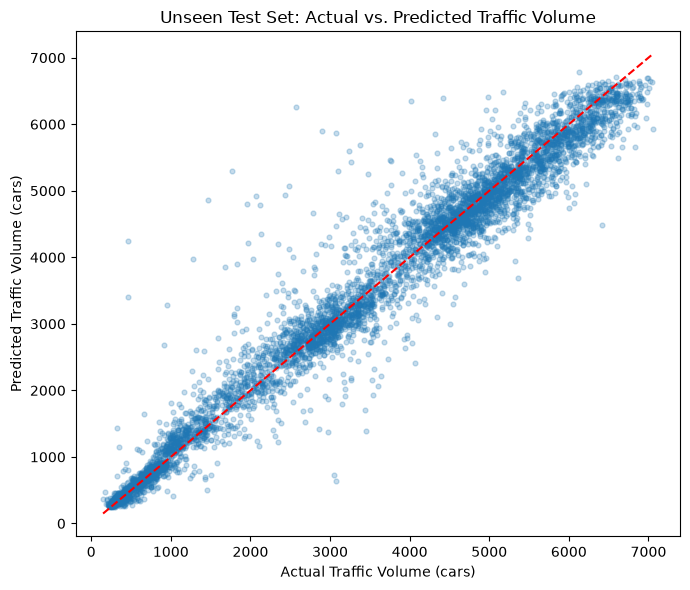

In [28]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.25, s=12)
line_min = min(float(y_test.min()), float(np.min(y_test_pred)))
line_max = max(float(y_test.max()), float(np.max(y_test_pred)))
plt.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--", linewidth=1.5)
plt.xlabel("Actual Traffic Volume (cars)")
plt.ylabel("Predicted Traffic Volume (cars)")
plt.title("Unseen Test Set: Actual vs. Predicted Traffic Volume")
plt.tight_layout()
plt.show()